## **WEEK 17-18**
**Ritisha 045**

Intro to PyTorch (or TensorFlow/Keras): tensors, autograd, training loop

CNNs: convolutions, pooling, image classification

RNNs/LSTMs/GRUs: sequence modeling basics

Regularization in DL: dropout, batch norm, early stopping

Transfer learning basics (pretrained CNNs)

Hugging Face transformers library basics

Using LLM APIs (OpenAI, Anthropic, open models via Hugging Face/Ollama)


In [ ]:
# Install extra libraries (torch/torchvision are preinstalled on Colab).
# transformers = Hugging Face models, anthropic/openai = LLM API clients.
!pip install -q transformers datasets anthropic openai

In [ ]:
# Import the core libraries used throughout the notebook.
# Also pick GPU if available, otherwise fall back to CPU.
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset, Subset, random_split
import torchvision
from torchvision import datasets, transforms, models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
print("PyTorch:", torch.__version__, "| Device:", device)

PyTorch: 2.11.0+cu130 | Device: cuda


---
## 1. PyTorch Basics: Tensors, Autograd and a Training Loop

### 1.1 Creating and manipulating tensors
Tensors are PyTorch's n-dimensional arrays. They support GPU acceleration and automatic differentiation.

In [ ]:
# Create tensors in several ways: from lists, zeros/ones, random, and from NumPy.
# Print shape and dtype, which are the two properties you check most often.
a = torch.tensor([[1., 2.], [3., 4.]])
b = torch.rand(2, 2)
z = torch.zeros(2, 3)
n = torch.from_numpy(np.arange(6).reshape(2, 3))
print("a:\n", a, "\nshape:", a.shape, "dtype:", a.dtype)
print("b:\n", b)
print("zeros:\n", z)
print("from numpy:\n", n)

a:
 tensor([[1., 2.],
        [3., 4.]]) 
shape: torch.Size([2, 2]) dtype: torch.float32
b:
 tensor([[0.8823, 0.9150],
        [0.3829, 0.9593]])
zeros:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])
from numpy:
 tensor([[0, 1, 2],
        [3, 4, 5]])


In [ ]:
# Tensor operations: element-wise math, matrix multiplication, reshaping, and slicing.
# These are the building blocks of every neural network layer.
print("a + b:\n", a + b)
print("a * b (element-wise):\n", a * b)
print("a @ b (matrix multiply):\n", a @ b)
print("reshape 4x1:\n", a.reshape(4, 1))
print("first row:", a[0], "| sum:", a.sum().item(), "| mean:", a.mean().item())

a + b:
 tensor([[1.8823, 2.9150],
        [3.3829, 4.9593]])
a * b (element-wise):
 tensor([[0.8823, 1.8300],
        [1.1486, 3.8372]])
a @ b (matrix multiply):
 tensor([[1.6480, 2.8336],
        [4.1783, 6.5822]])
reshape 4x1:
 tensor([[1.],
        [2.],
        [3.],
        [4.]])
first row: tensor([1., 2.]) | sum: 10.0 | mean: 2.5


In [ ]:
# Move a tensor to the GPU (if available) and back to CPU.
# Computation must happen on tensors that are on the same device.
x_dev = a.to(device)
print("Tensor device:", x_dev.device)
print("Back on CPU:", x_dev.cpu().device)

Tensor device: cuda:0
Back on CPU: cpu


### 1.2 Autograd: automatic differentiation
Setting `requires_grad=True` tells PyTorch to record operations so it can compute gradients with `.backward()`.

In [ ]:
# Compute the derivative of y = x^2 + 3x at x = 2 using autograd.
# Analytically dy/dx = 2x + 3 = 7, so x.grad should print 7.
x = torch.tensor(2.0, requires_grad=True)
y = x**2 + 3*x
y.backward()
print("dy/dx at x=2:", x.grad.item())

dy/dx at x=2: 7.0


In [ ]:
# Autograd with vectors: gradient of a scalar loss w.r.t. weights w.
# loss = sum((w*x - target)^2); the gradient flows back automatically.
w = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
inp = torch.tensor([0.5, 1.0, 1.5])
target = torch.tensor(4.0)
loss = ((w * inp).sum() - target) ** 2
loss.backward()
print("loss:", loss.item(), "\ngrad w:", w.grad)

loss: 9.0 
grad w: tensor([3., 6., 9.])


### 1.3 A basic training loop (linear regression)
The standard PyTorch loop: **forward pass → compute loss → zero gradients → backward pass → optimizer step**.

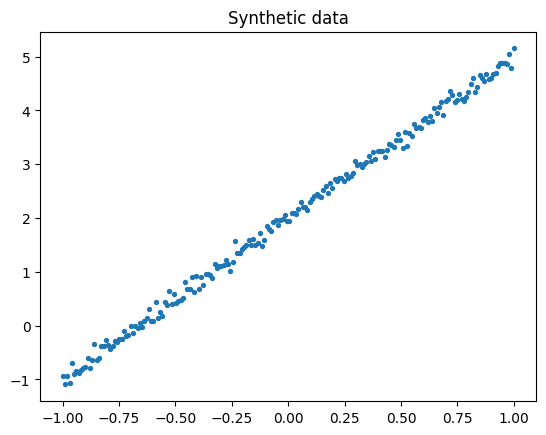

In [ ]:
# Generate synthetic data following y = 3x + 2 plus noise.
# The model should learn weight ~3 and bias ~2.
X = torch.linspace(-1, 1, 200).unsqueeze(1)
Y = 3 * X + 2 + 0.1 * torch.randn_like(X)
plt.scatter(X, Y, s=8); plt.title("Synthetic data"); plt.show()

In [ ]:
# Define model, loss function and optimizer, then run the training loop.
# Each epoch: predict, measure error (MSE), backpropagate, update weights.
model = nn.Linear(1, 1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

losses = []
for epoch in range(100):
    pred = model(X)                 # forward pass
    loss = loss_fn(pred, Y)         # compute loss
    optimizer.zero_grad()           # clear old gradients
    loss.backward()                 # backpropagation
    optimizer.step()                # update parameters
    losses.append(loss.item())
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1:3d} | loss = {loss.item():.4f}")

print("Learned weight:", model.weight.item(), "| bias:", model.bias.item())

Epoch  20 | loss = 0.3248
Epoch  40 | loss = 0.0280
Epoch  60 | loss = 0.0097
Epoch  80 | loss = 0.0086
Epoch 100 | loss = 0.0085
Learned weight: 2.9917373657226562 | bias: 2.0030434131622314


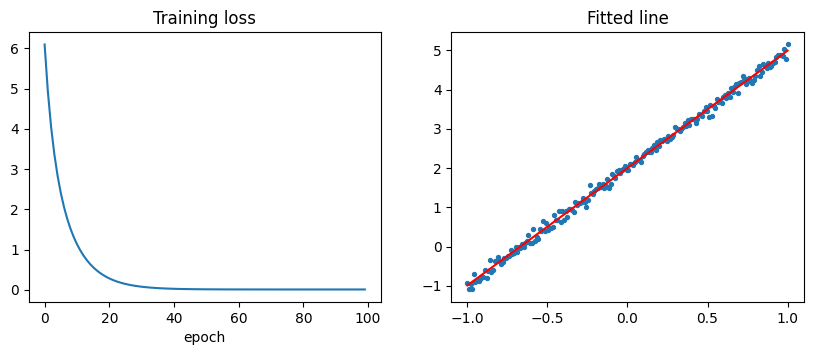

In [ ]:
# Visualize the loss curve and the fitted line against the data.
# A decreasing loss and a good fit confirm training worked.
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(losses); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].scatter(X, Y, s=8); ax[1].plot(X, model(X).detach(), "r"); ax[1].set_title("Fitted line")
plt.show()

---
## 2. Convolutional Neural Network (CNN) for Image Classification
We use **Fashion-MNIST** (28x28 grayscale images of clothing, 10 classes). A CNN uses *convolution* layers to detect local patterns and *pooling* layers to downsample.

In [ ]:
# Download Fashion-MNIST and wrap it in DataLoaders for batching.
# ToTensor converts images to [0,1] float tensors of shape (1, 28, 28).
tfm = transforms.ToTensor()
train_full = datasets.FashionMNIST("./data", train=True, download=True, transform=tfm)
test_ds = datasets.FashionMNIST("./data", train=False, download=True, transform=tfm)
train_loader = DataLoader(train_full, batch_size=128, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=256)
classes = train_full.classes
print("Train size:", len(train_full), "| Test size:", len(test_ds), "\nClasses:", classes)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 216kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.99MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.5MB/s]

Train size: 60000 | Test size: 10000 
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


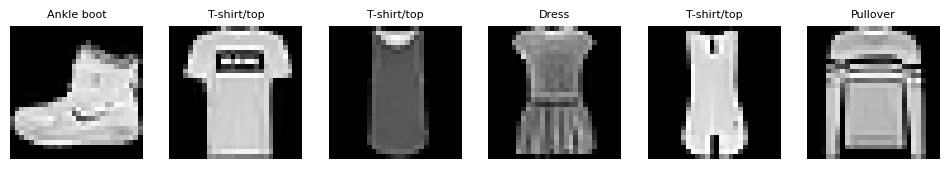

In [ ]:
# Show a few sample images with their labels.
# Always look at your data before training.
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for i, ax in enumerate(axes):
    img, label = train_full[i]
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(classes[label], fontsize=8); ax.axis("off")
plt.show()

In [ ]:
# Define a simple CNN: 2 x (Conv -> ReLU -> MaxPool) followed by fully connected layers.
# Conv extracts features; MaxPool halves spatial size (28 -> 14 -> 7).
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # (B,16,14,14)
        x = self.pool(F.relu(self.conv2(x)))   # (B,32,7,7)
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

cnn = SimpleCNN().to(device)
print(cnn)
print("Parameters:", sum(p.numel() for p in cnn.parameters()))

SimpleCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Parameters: 206922


In [ ]:
# Reusable helper functions for one training epoch and for evaluation.
# They return average loss and accuracy, and we reuse them in later sections.
def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss, correct, n = 0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = loss_fn(out, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
        correct += (out.argmax(1) == yb).sum().item()
        n += len(xb)
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, n = 0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total_loss += loss_fn(out, yb).item() * len(xb)
        correct += (out.argmax(1) == yb).sum().item()
        n += len(xb)
    return total_loss / n, correct / n

In [ ]:
# Train the CNN for 5 epochs with Adam and cross-entropy loss.
# We print train/test accuracy per epoch and keep history for plotting.
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
hist = {"tr_acc": [], "te_acc": []}
for epoch in range(5):
    tr_loss, tr_acc = train_one_epoch(cnn, train_loader, opt, loss_fn)
    te_loss, te_acc = evaluate(cnn, test_loader, loss_fn)
    hist["tr_acc"].append(tr_acc); hist["te_acc"].append(te_acc)
    print(f"Epoch {epoch+1} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | test loss {te_loss:.3f} acc {te_acc:.3f}")

Epoch 1 | train loss 0.582 acc 0.792 | test loss 0.407 acc 0.852
Epoch 2 | train loss 0.358 acc 0.871 | test loss 0.356 acc 0.870
Epoch 3 | train loss 0.311 acc 0.887 | test loss 0.310 acc 0.888
Epoch 4 | train loss 0.280 acc 0.898 | test loss 0.294 acc 0.891
Epoch 5 | train loss 0.257 acc 0.906 | test loss 0.275 acc 0.901


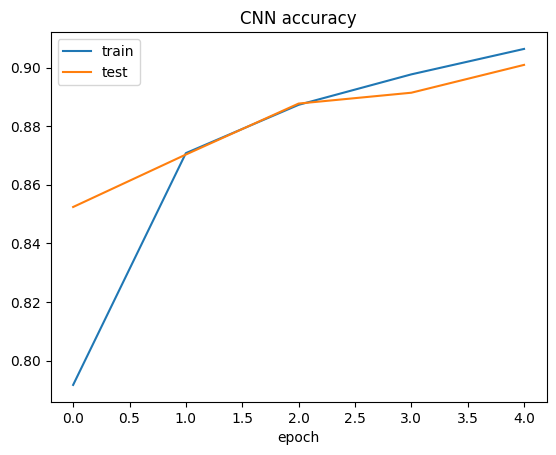

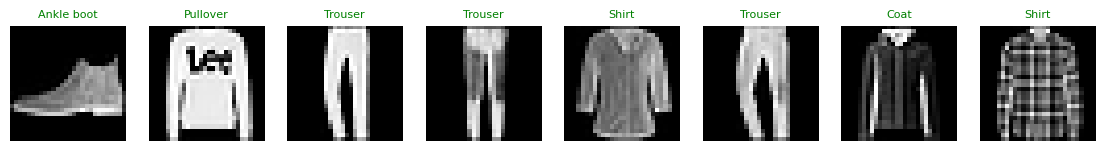

In [ ]:
# Plot accuracy curves and show predictions on a few test images.
# Green titles = correct prediction, red = wrong.
plt.plot(hist["tr_acc"], label="train"); plt.plot(hist["te_acc"], label="test")
plt.legend(); plt.title("CNN accuracy"); plt.xlabel("epoch"); plt.show()

cnn.eval()
fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
for i, ax in enumerate(axes):
    img, label = test_ds[i]
    pred = cnn(img.unsqueeze(0).to(device)).argmax(1).item()
    ax.imshow(img.squeeze(), cmap="gray"); ax.axis("off")
    ax.set_title(classes[pred], fontsize=8, color="green" if pred == label else "red")
plt.show()

---
## 3. Sequence Modeling: RNN, LSTM and GRU
Task: given the last 20 values of a noisy sine wave, predict the next value. We compare the three recurrent architectures.

In [ ]:
# Build a noisy sine-wave series and slice it into (window -> next value) samples.
# 80% is used for training and the final 20% (later in time) for testing.
t = np.linspace(0, 100, 2000)
series = np.sin(t) + 0.1 * np.random.randn(len(t))

def make_windows(s, w=20):
    Xs = np.stack([s[i:i+w] for i in range(len(s) - w)])
    ys = s[w:]
    return torch.tensor(Xs, dtype=torch.float32).unsqueeze(-1), torch.tensor(ys, dtype=torch.float32).unsqueeze(-1)

Xs, ys = make_windows(series)
split = int(0.8 * len(Xs))
seq_train = DataLoader(TensorDataset(Xs[:split], ys[:split]), batch_size=64, shuffle=True)
Xte, yte = Xs[split:].to(device), ys[split:].to(device)
print("Input shape:", Xs.shape, "| Target shape:", ys.shape)

Input shape: torch.Size([1980, 20, 1]) | Target shape: torch.Size([1980, 1])


In [ ]:
# One flexible model class that can use RNN, LSTM or GRU as its recurrent layer.
# The last hidden output of the sequence is passed to a linear layer to predict the next value.
class SeqModel(nn.Module):
    def __init__(self, kind="LSTM", hidden=32):
        super().__init__()
        layer = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind]
        self.rnn = layer(input_size=1, hidden_size=hidden, num_layers=1, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)          # out: (B, T, hidden)
        return self.fc(out[:, -1])    # use last time step

print(SeqModel("GRU"))

SeqModel(
  (rnn): GRU(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


In [ ]:
# Train RNN, LSTM and GRU for 15 epochs each and record test MSE.
# This lets us compare how well each architecture models the sequence.
results, preds = {}, {}
for kind in ["RNN", "LSTM", "GRU"]:
    torch.manual_seed(0)
    m = SeqModel(kind).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-2)
    mse = nn.MSELoss()
    for epoch in range(15):
        m.train()
        for xb, yb in seq_train:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = mse(m(xb), yb); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        p = m(Xte)
    results[kind] = mse(p, yte).item(); preds[kind] = p.cpu().squeeze()
    print(f"{kind:5s} test MSE: {results[kind]:.4f}")

RNN   test MSE: 0.0148
LSTM  test MSE: 0.0142
GRU   test MSE: 0.0132


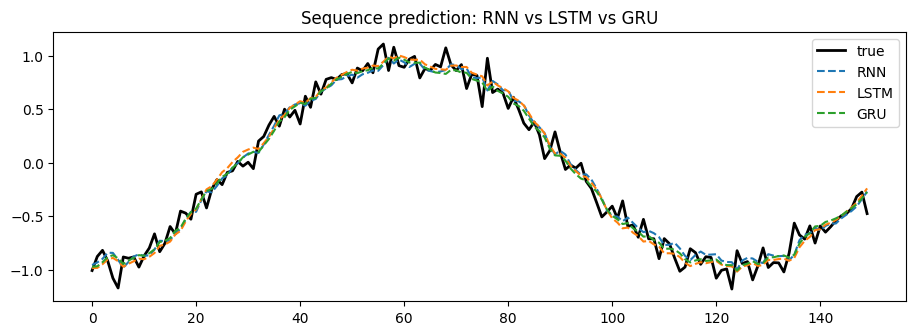

In [ ]:
# Plot the first 150 test predictions from each model against the true values.
# Good models should track the sine wave closely.
plt.figure(figsize=(11, 3.5))
plt.plot(yte.cpu().squeeze()[:150], "k", label="true", linewidth=2)
for kind, p in preds.items():
    plt.plot(p[:150], "--", label=kind)
plt.legend(); plt.title("Sequence prediction: RNN vs LSTM vs GRU"); plt.show()

---
## 4. Regularization: Dropout, Batch Normalization and Early Stopping
- **Dropout** randomly zeroes activations during training, which reduces co-adaptation.
- **Batch normalization** normalizes layer inputs, which stabilizes and speeds up training.
- **Early stopping** halts training when validation loss stops improving.

In [ ]:
# Split training data into train/validation sets (needed for early stopping).
# Validation data is used only to monitor generalization, never to update weights.
train_ds, val_ds = random_split(train_full, [54000, 6000], generator=torch.Generator().manual_seed(1))
tr_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=256)
print(len(train_ds), len(val_ds))

54000 6000


In [ ]:
# Define a CNN that adds BatchNorm2d after convolutions and Dropout before the classifier.
# Compare its structure with SimpleCNN above.
class RegCNN(nn.Module):
    def __init__(self, p=0.4):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1); self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1); self.bn2 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2, 2)
        self.drop = nn.Dropout(p)
        self.fc1 = nn.Linear(64 * 7 * 7, 128); self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.drop(x.flatten(1))
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)

print(RegCNN())

RegCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop): Dropout(p=0.4, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
# An EarlyStopping helper: tracks best validation loss and stores the best weights.
# Training stops after `patience` epochs with no improvement.
import copy
class EarlyStopping:
    def __init__(self, patience=3, min_delta=1e-4):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.counter, self.best_state = float("inf"), 0, None

    def step(self, val_loss, model):
        if val_loss < self.best - self.min_delta:
            self.best, self.counter = val_loss, 0
            self.best_state = copy.deepcopy(model.state_dict())
            return False
        self.counter += 1
        return self.counter >= self.patience

In [ ]:
# Train RegCNN for up to 30 epochs with weight decay (L2 regularization) and early stopping.
# The best weights are restored when training ends.
reg_model = RegCNN().to(device)
opt = torch.optim.Adam(reg_model.parameters(), lr=1e-3, weight_decay=1e-4)
stopper = EarlyStopping(patience=3)
h = {"tr": [], "val": []}
for epoch in range(30):
    tr_loss, tr_acc = train_one_epoch(reg_model, tr_loader, opt, loss_fn)
    v_loss, v_acc = evaluate(reg_model, val_loader, loss_fn)
    h["tr"].append(tr_loss); h["val"].append(v_loss)
    print(f"Epoch {epoch+1:2d} | train {tr_loss:.3f} | val {v_loss:.3f} (acc {v_acc:.3f})")
    if stopper.step(v_loss, reg_model):
        print(f"Early stopping at epoch {epoch+1}. Best val loss: {stopper.best:.3f}")
        break

reg_model.load_state_dict(stopper.best_state)
print("Final test accuracy:", evaluate(reg_model, test_loader, loss_fn)[1])

Epoch  1 | train 0.490 | val 0.331 (acc 0.875)
Epoch  2 | train 0.353 | val 0.279 (acc 0.894)
Epoch  3 | train 0.311 | val 0.257 (acc 0.904)
Epoch  4 | train 0.289 | val 0.252 (acc 0.902)
Epoch  5 | train 0.269 | val 0.245 (acc 0.906)
Epoch  6 | train 0.256 | val 0.226 (acc 0.913)
Epoch  7 | train 0.245 | val 0.221 (acc 0.916)
Epoch  8 | train 0.234 | val 0.236 (acc 0.911)
Epoch  9 | train 0.226 | val 0.224 (acc 0.918)
Epoch 10 | train 0.222 | val 0.244 (acc 0.907)
Early stopping at epoch 10. Best val loss: 0.221
Final test accuracy: 0.9139


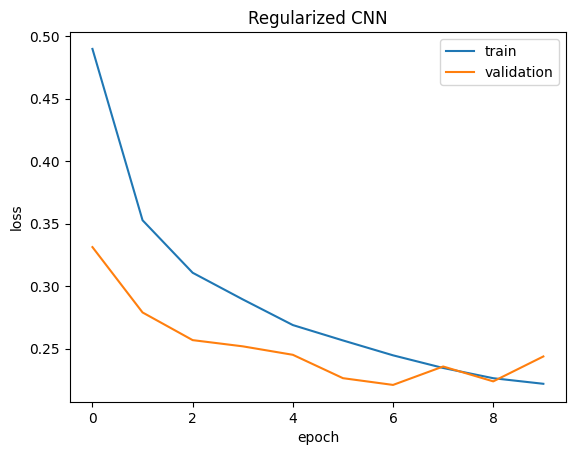

In [ ]:
# Plot training vs validation loss to see how well the model generalizes.
# A small gap between curves means little overfitting.
plt.plot(h["tr"], label="train"); plt.plot(h["val"], label="validation")
plt.legend(); plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Regularized CNN"); plt.show()

---
## 5. Transfer Learning with a Pretrained CNN (ResNet18)
Instead of training from scratch, we reuse a ResNet18 trained on ImageNet. We **freeze** the convolutional backbone and train only a new final classification layer for **CIFAR-10**.

In [ ]:
# Load CIFAR-10 with the preprocessing ResNet expects: resize and ImageNet normalization.
# We use small subsets so the demo runs quickly even on a free Colab GPU.
imnet_tfm = transforms.Compose([
    transforms.Resize(112),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
c_train = datasets.CIFAR10("./data", train=True, download=True, transform=imnet_tfm)
c_test = datasets.CIFAR10("./data", train=False, download=True, transform=imnet_tfm)
c_train_loader = DataLoader(Subset(c_train, range(5000)), batch_size=64, shuffle=True)
c_test_loader = DataLoader(Subset(c_test, range(1000)), batch_size=128)
print("CIFAR-10 classes:", c_train.classes)

100%|██████████| 170M/170M [34:20<00:00, 82.8kB/s]


CIFAR-10 classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
# Load pretrained ResNet18, freeze all its layers, and replace the final layer with a 10-class head.
# Only the new `fc` layer has requires_grad=True, so only it will be trained.
tl_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in tl_model.parameters():
    p.requires_grad = False
tl_model.fc = nn.Linear(tl_model.fc.in_features, 10)
tl_model = tl_model.to(device)

trainable = sum(p.numel() for p in tl_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in tl_model.parameters())
print(f"Trainable params: {trainable:,} / {total:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 139MB/s]

Trainable params: 5,130 / 11,181,642


In [ ]:
# Train only the new classifier head for 3 epochs and evaluate on the test subset.
# Even with a frozen backbone, accuracy is high because ImageNet features transfer well.
opt = torch.optim.Adam(tl_model.fc.parameters(), lr=1e-3)
for epoch in range(3):
    tr_loss, tr_acc = train_one_epoch(tl_model, c_train_loader, opt, loss_fn)
    te_loss, te_acc = evaluate(tl_model, c_test_loader, loss_fn)
    print(f"Epoch {epoch+1} | train acc {tr_acc:.3f} | test acc {te_acc:.3f}")

Epoch 1 | train acc 0.505 | test acc 0.665
Epoch 2 | train acc 0.712 | test acc 0.705
Epoch 3 | train acc 0.746 | test acc 0.722


In [ ]:
# (Optional) Fine-tuning: unfreeze the last residual block and train with a small learning rate.
# This adapts higher-level features to the new dataset for extra accuracy.
for p in tl_model.layer4.parameters():
    p.requires_grad = True
opt = torch.optim.Adam([
    {"params": tl_model.layer4.parameters(), "lr": 1e-4},
    {"params": tl_model.fc.parameters(), "lr": 1e-3},
])
for epoch in range(2):
    tr_loss, tr_acc = train_one_epoch(tl_model, c_train_loader, opt, loss_fn)
    te_loss, te_acc = evaluate(tl_model, c_test_loader, loss_fn)
    print(f"Fine-tune epoch {epoch+1} | train acc {tr_acc:.3f} | test acc {te_acc:.3f}")

Fine-tune epoch 1 | train acc 0.808 | test acc 0.828
Fine-tune epoch 2 | train acc 0.975 | test acc 0.844


---
## 6. Hugging Face Transformers Basics
The `pipeline` API gives one-line access to pretrained transformer models. Under the hood it does: **tokenize → model → post-process**.

In [ ]:
# Use a ready-made sentiment-analysis pipeline (downloads a pretrained DistilBERT model).
# Input is plain text; output is a label and confidence score.
from transformers import pipeline
sentiment = pipeline("sentiment-analysis")
texts = ["I loved this course, the labs were fantastic!", "The wifi kept dropping and the session was a waste of time."]
for t_, r in zip(texts, sentiment(texts)):
    print(f"{r['label']:8s} ({r['score']:.3f}) -> {t_}")

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

POSITIVE (1.000) -> I loved this course, the labs were fantastic!
NEGATIVE (1.000) -> The wifi kept dropping and the session was a waste of time.


In [ ]:
# Try two more tasks with pipelines: named entity recognition and zero-shot classification.
# Zero-shot lets you classify text into labels the model was never trained on.
ner = pipeline("ner", aggregation_strategy="simple")
print(ner("Sundar Pichai announced new Google offices in Pune and Bengaluru."))

zs = pipeline("zero-shot-classification")
res = zs("The new GPU doubles training speed for neural networks.", candidate_labels=["technology", "sports", "politics"])
print(res["labels"], [round(s, 3) for s in res["scores"]])

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

['technology', 'sports', 'politics'] [0.991, 0.006, 0.003]


In [ ]:
# Peek under the hood: tokenize text and run the model manually.
# Tokenizer -> input IDs -> model logits -> softmax probabilities.
from transformers import AutoTokenizer, AutoModelForSequenceClassification
name = "distilbert-base-uncased-finetuned-sst-2-english"
tok = AutoTokenizer.from_pretrained(name)
hf_model = AutoModelForSequenceClassification.from_pretrained(name).eval()

enc = tok("Transformers make NLP so much easier!", return_tensors="pt")
print("Tokens:", tok.convert_ids_to_tokens(enc["input_ids"][0]))
with torch.no_grad():
    logits = hf_model(**enc).logits
probs = F.softmax(logits, dim=-1)[0]
print({hf_model.config.id2label[i]: round(p.item(), 3) for i, p in enumerate(probs)})

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Tokens: ['[CLS]', 'transformers', 'make', 'nl', '##p', 'so', 'much', 'easier', '!', '[SEP]']
{'NEGATIVE': 0.02, 'POSITIVE': 0.98}


In [ ]:
# Use a pretrained model for text summarization (a seq2seq transformer).
# We use a small distilled model so it loads quickly.
from transformers import pipeline

generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-0.5B-Instruct"
)

article = """
Deep learning is a subset of machine learning that uses neural networks
with many layers. It has driven breakthroughs in computer vision,
speech recognition, and natural language processing. Frameworks such
as PyTorch and TensorFlow make it easy to build and train models.
"""

prompt = [
    {
        "role": "user",
        "content": "Summarize this text in 3 short sentences:\n" + article
    }
]

result = generator(
    prompt,
    max_new_tokens=100,
    do_sample=False
)

print(result[0]["generated_text"][-1]["content"])

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Deep learning is a branch of machine learning that utilizes neural networks with multiple layers, leading to significant advancements in computer vision, speech recognition, and natural language processing tasks. Frameworks like PyTorch and TensorFlow simplify the development and training of these models.


---
## 7. Using LLM APIs (Anthropic, OpenAI, Open Models)

**Store API keys safely:** click the 🔑 *Secrets* icon in the Colab left sidebar, add `ANTHROPIC_API_KEY` and/or `OPENAI_API_KEY`, and toggle *Notebook access* on. Never paste keys directly into code.

In [ ]:
# Description:
# This code checks whether API keys are available in Google Colab Secrets.
# It loads the keys into environment variables if they exist.
# API keys are not required for the local Hugging Face model.

import os
from google.colab import userdata

for key in ["ANTHROPIC_API_KEY", "OPENAI_API_KEY"]:
    try:
        value = userdata.get(key)
        if value:
            os.environ[key] = value
            print(key, "loaded successfully")
        else:
            print(key, "not configured")
    except Exception:
        print(key, "not configured")

ANTHROPIC_API_KEY not configured
OPENAI_API_KEY not configured


In [ ]:
# Description:
# This code loads a small pretrained language model from Hugging Face.
# It generates a response to a user-provided question.
# No OpenAI or Anthropic API key is required.

from transformers import pipeline

# Load the pretrained language model
generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-0.5B-Instruct"
)

# Define a question for the model
messages = [
    {
        "role": "user",
        "content": "Give one tip to avoid overfitting in deep learning."
    }
]

# Generate the response
output = generator(
    messages,
    max_new_tokens=80,
    do_sample=False
)

# Display the generated answer
print(output[0]["generated_text"][-1]["content"])

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

One effective way to avoid overfitting in deep learning is through regularization techniques such as dropout and L1/L2 regularization. These methods help prevent the model from becoming too complex and can lead to better generalization performance on unseen data. Additionally, it's important to use techniques like early stopping or validation during training to monitor and adjust the model's parameters dynamically.


---
## Summary
| Topic | Key idea |
|---|---|
| Tensors & autograd | Tensors hold data; `.backward()` computes gradients automatically |
| Training loop | forward → loss → `zero_grad` → `backward` → `step` |
| CNN | Convolutions learn local features; pooling downsamples |
| RNN/LSTM/GRU | Process sequences step by step; gated units handle long-range dependencies |
| Regularization | Dropout, BatchNorm, weight decay and early stopping reduce overfitting |
| Transfer learning | Reuse pretrained features, train only a new head (then optionally fine-tune) |
| Hugging Face | `pipeline` for quick tasks; Auto classes for full control |
| LLM APIs | Hosted APIs (Anthropic, OpenAI) vs. local open models (Hugging Face, Ollama) |